# Exercice 2 : Une photo révèle où elle a été prise

> **En une phrase :** une photo contient souvent, cachées dans ses **métadonnées EXIF**, l'heure, l'appareil et les **coordonnées GPS** où elle a été prise.

**Le scénario.** En 2012, John McAfee est en fuite. Un média publie une photo de lui : les coordonnées GPS dans le fichier le localisent au Guatemala. Aucun piratage : juste un fichier publié.

**La donnée.** Une vraie photo prise avec un Nikon COOLPIX P6000 en 2008, issue d'un jeu d'exemples public (`ianare/exif-samples`).

**Le plan.**
1. Télécharger la photo.
2. Lire ses métadonnées.
3. Convertir le GPS et le placer sur une carte.
4. Contre-mesure : effacer les métadonnées et vérifier.

## Étape 0 : exécutez cette cellule en premier
Le notebook est **autonome** : il fonctionne tel quel sur Colab (ouvert depuis Drive) ou en local. Elle doit afficher **Prêt**.

In [1]:
import io, requests
from PIL import Image, ExifTags
from IPython.display import display
print('Prêt')

Prêt


## Étape 1 : Télécharger la photo
**Ce qu'on fait :** on récupère la photo comme le ferait n'importe quel visiteur d'un site web.

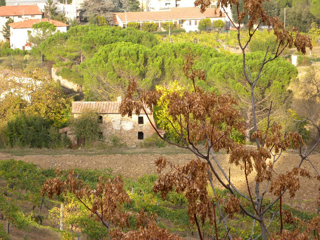

In [2]:
url = "https://raw.githubusercontent.com/ianare/exif-samples/master/jpg/gps/DSCN0010.jpg"   # <-- MODIFIABLE
photo = Image.open(io.BytesIO(requests.get(url, timeout=20).content))
display(photo.resize((320, 240)))

**👀 Ce qu'on doit voir :** une photo de paysage, rien d'autre en apparence.

## Étape 2 : Lire les métadonnées EXIF
**Ce qu'on fait :** on affiche ce que l'appareil a écrit **dans** le fichier, en plus de l'image.

In [3]:
exif = photo.getexif()
for cle, valeur in exif.items():
    nom = ExifTags.TAGS.get(cle, cle)
    if nom in ("Make", "Model", "Software", "DateTime"):
        print(f"{nom:10} : {valeur}")

gps = {ExifTags.GPSTAGS.get(k, k): v for k, v in exif.get_ifd(0x8825).items()}
print()
for k in ("GPSLatitudeRef", "GPSLatitude", "GPSLongitudeRef", "GPSLongitude", "GPSDateStamp"):
    print(f"{k:16} : {gps.get(k)}")

Make       : NIKON
Model      : COOLPIX P6000
Software   : Nikon Transfer 1.1 W
DateTime   : 2008:11:01 21:15:07

GPSLatitudeRef   : N
GPSLatitude      : (43.0, 28.0, 2.814)
GPSLongitudeRef  : E
GPSLongitude     : (11.0, 53.0, 6.45599999)
GPSDateStamp     : 2008:10:23


**👀 Ce qu'on doit voir :** l'appareil (**NIKON COOLPIX P6000**), le logiciel, la date (**2008-11-01**), et une latitude/longitude en degrés, minutes, secondes : **43° 28' 2.8" N, 11° 53' 6.5" E**.

## Étape 3 : Placer le GPS sur une carte
**Ce qu'on fait :** on convertit degrés/minutes/secondes en nombre décimal, puis on construit un lien de carte.

In [4]:
def en_decimal(dms, ref):
    degres, minutes, secondes = (float(x) for x in dms)
    valeur = degres + minutes / 60 + secondes / 3600
    return -valeur if ref in ("S", "W") else valeur

lat = en_decimal(gps["GPSLatitude"], gps["GPSLatitudeRef"])
lon = en_decimal(gps["GPSLongitude"], gps["GPSLongitudeRef"])
print(f"Coordonnées : {lat:.5f}, {lon:.5f}")
print(f"Carte       : https://www.openstreetmap.org/?mlat={lat:.5f}&mlon={lon:.5f}#map=15/{lat:.5f}/{lon:.5f}")

Coordonnées : 43.46745, 11.88513
Carte       : https://www.openstreetmap.org/?mlat=43.46745&mlon=11.88513#map=15/43.46745/11.88513


**👀 Ce qu'on doit voir :** **43.46745, 11.88513**. En ouvrant le lien : la Toscane, en Italie, près d'Arezzo. À quelques mètres près.

**❓ Question pour la classe :** les réseaux sociaux (Facebook, Instagram) retirent l'EXIF des photos publiées. Alors où l'attaquant trouve-t-il encore des photos avec GPS ?

*Pistes : les sites web d'entreprise (pages « équipe », actualités), les petites annonces, les pièces jointes de courriel, les documents PDF et Word (qui ont aussi des métadonnées : auteur, logiciel, chemin du fichier).*

## Étape 4 : Contre-mesure : effacer les métadonnées
**Ce qu'on fait :** on recrée l'image **pixel par pixel**, sans copier les métadonnées, puis on vérifie.

In [5]:
propre = Image.frombytes(photo.mode, photo.size, photo.tobytes())   # seulement les pixels
tampon = io.BytesIO()
propre.save(tampon, format="JPEG")

verif = Image.open(io.BytesIO(tampon.getvalue())).getexif()
print("Métadonnées avant :", len(exif), "champs, GPS présent :", 0x8825 in exif)
print("Métadonnées après :", len(verif), "champs, GPS présent :", 0x8825 in verif)

Métadonnées avant : 12 champs, GPS présent : True
Métadonnées après : 0 champs, GPS présent : False


**👀 Ce qu'on doit voir :** avant : **12 champs**, GPS présent : **True**. Après : **0 champs**, GPS présent : **False**.

## Ce qu'il faut retenir
- Un fichier contient plus que ce qu'il montre : **EXIF** pour les photos, **auteur et logiciel** pour les documents.
- Une seule photo peut révéler **où**, **quand** et **avec quoi** : utile pour localiser une personne ou connaître le matériel d'une entreprise.
- Contre-mesure simple : **effacer les métadonnées avant de publier**, et l'automatiser sur le site web de l'organisation.

**Exercice suivant :** on passe des personnes à l'organisation. Que révèle un simple nom de domaine ?